# TF–DNA predictions at mouse CUT&RUN binding sites (mm10)

This notebook evaluates the **mm10 TF–DNA checkpoint `mm10_3925194_epoch_21.ckpt`** on published mouse CUT&RUN peaks. Its analysis cells are the same as in `tf_dna_vs_cut&run_hg38.ipynb` (hg38); only the datasets, chromosomes, and checkpoint differ.

The question is whether the trained sequence model ranks experimentally bound windows above chromosome- and GC-matched genomic background, and whether it does better than a single motif scan of the same windows.

Run every code cell on an HPC **compute node**. No model fitting or threshold tuning is performed here. Primary analyses use the mm10 test chromosomes **chr18 and chr19**, conditional on an audit of the saved training and validation splits.

In [1]:
from pathlib import Path
import os
import socket
import sys

os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]

# Stop before importing scientific packages if the notebook is opened on a gateway.
if "hgtw" in socket.gethostname().lower() or "gtwy" in socket.gethostname().lower():
    raise RuntimeError("Run this notebook on a Slurm compute node")

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
TETHER_DIR = PROJECT_DIR / "TETHER"
DATA_DIR = PROJECT_DIR / "data"
GENOME = "mm10"
sys.path.insert(0, str(TETHER_DIR))

import config

# Byte-identical copy of checkpoints/tf_dna_mm10_3925194/epoch_21.ckpt.
tf_dna_model_path = Path(config.CHKPT_DIR) / "new_tf_dna_models" / "mm10_3925194_epoch_21.ckpt"
# The TF-DNA training cache of this genome (TF table, embeddings, splits).
tf_dna_input_cache_dir = config.tf_dna_cache_dir(GENOME)

cutrun_data_dir = DATA_DIR / "CUT&RUN_data" / "mm10"
tf_embedding_dir = DATA_DIR / "tf_data" / GENOME / "tf_embeddings"
cisbp_motif_dir = DATA_DIR / "databases" / "motif_information" / GENOME
genome_fasta_path = DATA_DIR / "genome_data" / "reference_genome" / GENOME / f"{GENOME}.fa"

run_label = f"tf_dna_cutrun_{GENOME}_{tf_dna_model_path.stem}"
evaluation_result_dir = TETHER_DIR / "new_testing_results" / run_label
evaluation_figure_dir = TETHER_DIR / "new_plots" / run_label
evaluation_result_dir.mkdir(parents=True, exist_ok=True)
evaluation_figure_dir.mkdir(parents=True, exist_ok=True)

import bisect
import gzip
import hashlib
import json
import logging
import platform
import re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import sklearn
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import pysam
from IPython.display import display, Markdown
from sklearn.metrics import (
    roc_curve, precision_recall_curve, roc_auc_score,
    average_precision_score, confusion_matrix,
)
import utils
from matplotlib_inline import backend_inline

get_ipython().run_line_magic("matplotlib", "inline")
backend_inline.set_matplotlib_formats("svg")

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logging.getLogger("fontTools").setLevel(logging.WARNING)

RANDOM_SEED = 42
EVALUATION_CHROMOSOMES = ('chr18', 'chr19')
DNA_WINDOW_LENGTH = 256
GC_MATCH_TOLERANCE = 0.02
MAXIMUM_MATCH_ATTEMPTS = 5000
INFERENCE_BATCH_SIZE = 128
BOOTSTRAP_REPLICATES = 500

torch.manual_seed(RANDOM_SEED)
torch.set_num_threads(min(4, int(os.environ.get("SLURM_CPUS_PER_TASK", "4"))))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Host: {socket.gethostname()} | device: {device}")
print(f"Checkpoint: {tf_dna_model_path}")
print(f"TF-DNA cache: {tf_dna_input_cache_dir}")

Host: psh01com1hgpu01 | device: cuda
Checkpoint: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/checkpoints/new_tf_dna_models/mm10_3925194_epoch_21.ckpt
TF-DNA cache: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/cached_data/mm10/tf_dna_cache


## Data sources and scope

| Dataset | TF | GEO | Biological material | Peaks |
|---|---|---|---|---|
| Nanog_ESC_rep1 | Nanog | [GSM5484582](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5484582) | Mouse ES cells, before GATA6 induction (0 h), replicate 1 | Author-supplied narrowPeak, mm10 |
| Nanog_ESC_rep2 | Nanog | [GSM5484583](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5484583) | Same condition, replicate 2 | Author-supplied narrowPeak, mm10 |
| Ctcf_AgRP | Ctcf | [GSM7698720](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7698720) | AgRP neurons, 3,000 nuclei | Author-filtered narrowPeak, mm10 |
| Ctcf_cerebellum | Ctcf | [GSM7698722](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7698722) | Whole cerebellum, 10,000 nuclei | Author-filtered narrowPeak, mm10 |

NANOG data come from [GSE181104](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE181104) and [Thompson et al., 2022](https://doi.org/10.1038/s41467-022-31938-5). NANOG is a lineage-restricted pluripotency regulator; the uninduced 0-hour condition avoids interpreting forced GATA6 expression as an endogenous NANOG state. CTCF data come from [GSE240484](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE240484) (MACS2 peaks filtered with pseudoreplicates). The two CTCF samples are distinct biological materials, not replicates; both are primary.

The primary NANOG set is **replicate-1 peaks that overlap a replicate-2 peak by at least one base** (`Nanog_ESC_reproducible`). This is a reproducibility filter, **not an IDR analysis**. These GEO series deposit no IgG or untagged-antibody peaks, so the hg38 no-TF control (wild-type anti-V5 peaks) **has no mm10 counterpart**.

Download commands are in `data/CUT&RUN_data/mm10/download_instructions.txt`; GEO SOFT metadata and SHA-256 checksums are kept beside the data in `data/CUT&RUN_data/mm10/`. The [ENCODE mm10 blacklist v2](https://github.com/Boyle-Lab/Blacklist) removes problematic regions from both classes. Local reference lengths are checked against [UCSC mm10](https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes).

In [ ]:
def generate_random_sequence_for_motif_pwm(motifs, selected_tf_name):
    """
    Generate a one-hot encoded sequence from the PWM of the selected TF.

    Parameters:
    motifs (dict): A dictionary containing motifs for various TFs.
    selected_tf_name (str): The name of the selected TF.

    Returns:
    np.ndarray: A one-hot encoded sequence based on the PWM of the selected TF.
    """
    # Get the nucleotide frequency matrix (PWM) for the selected TF
    tf_motif = motifs[selected_tf_name]["pwm"]
    
    # Sample one base per position, using each PWM row as the base probabilities
    nuc_ids = [np.random.choice(4, p=row) for row in tf_motif]
    peak_nuc_key = ["A", "C", "G", "T"]
    pwm_seq = "".join([peak_nuc_key[nuc_id] for nuc_id in nuc_ids])

    return pwm_seq


def generate_max_pwm_sequence(motif_pwm):
    """
    Generate a DNA sequence that maximizes the PWM score.

    Parameters:
    motif_pwm (np.ndarray): The position weight matrix (PWM) for the motif.

    Returns:
    str: A DNA sequence that maximizes the PWM score.
    """
    # Get the index of the maximum value in each row of the PWM
    max_indices = np.argmax(motif_pwm, axis=1)

    # Map indices to nucleotides
    nuc_ids = max_indices
    peak_nuc_key = ["A", "C", "G", "T"]
    
    # Create the DNA sequence by joining the nucleotides corresponding to the max indices
    pwm_seq = "".join([peak_nuc_key[nuc_id] for nuc_id in nuc_ids])

    return pwm_seq


def calculate_pwm_motif_score(motif_pwm, dna_sequence):
    """
    Calculate the PWM motif score for a given DNA sequence.

    Parameters:
    motif_pwm (np.ndarray): The position weight matrix (PWM) for the motif.
    dna_sequence (str): The DNA sequence to score.

    Returns:
    float: The PWM motif score for the given DNA sequence.
    """
    # Convert the DNA sequence to a one-hot encoded representation
    one_hot_sequence = utils.onehot_dna_sequence(dna_sequence)
    
    dna_seq_length = one_hot_sequence.shape[0]
    motif_length = motif_pwm.shape[0]
    
    windows = np.arange(0, dna_seq_length - motif_length + 1, 1)
    
    pwm_scores = np.zeros(windows.shape[0])
    for pos in windows:
        window_dna = one_hot_sequence[pos:pos + motif_length]
        pwm_score = np.sum(motif_pwm * window_dna)
        pwm_scores[pos] = pwm_score

    total_score = np.sum(pwm_scores)
    
    return total_score, pwm_scores


def generate_random_background_dna_sequence(background_seqs: list) -> str:
    """
    Draw one random background DNA sequence from a pool of mm10-like sequences.

    Parameters:
    background_seqs (list): Background DNA sequences (str), all the same length.

    Returns:
    str: A randomly selected background DNA sequence.
    """
    if not background_seqs:
        raise ValueError("The list of background sequences is empty.")
    return background_seqs[np.random.randint(len(background_seqs))]


HOMER_BG_FASTA = DATA_DIR / "genome_data" / "homer_background" / "mm10" / "mm10_256bp.bg.sequences.fasta"
with open(HOMER_BG_FASTA) as f:
    MM10_BG_SEQS = [line.strip().upper() for line in f if line.strip() and not line.startswith(">")]


tf_names = ["Nanog", "Ctcf"]



In [ ]:
cutrun_dataset_definitions = [
    dict(dataset="Nanog_ESC_rep1", tf_name="Nanog", series="GSE181104", geo_samples=["GSM5484582"],
         title_keyword="Nanog_0h_rep1", assembly="mm10", file_format="narrowPeak", role="replicate",
         exclusion_group="Nanog", files=["GSM5484582_DL_44_CR_Nanog_0h_rep1_peaks.narrowPeak.gz"]),
    dict(dataset="Nanog_ESC_rep2", tf_name="Nanog", series="GSE181104", geo_samples=["GSM5484583"],
         title_keyword="Nanog_0h_rep2", assembly="mm10", file_format="narrowPeak", role="replicate",
         exclusion_group="Nanog", files=["GSM5484583_DL_45_CR_Nanog_0h_rep2_peaks.narrowPeak.gz"]),
    dict(dataset="Ctcf_AgRP", tf_name="Ctcf", series="GSE240484", geo_samples=["GSM7698720"],
         title_keyword="CTCF CUT&RUN", assembly="mm10", file_format="narrowPeak", role="primary",
         exclusion_group="Ctcf", files=["GSE240484_CUT-RUN.CTCF.Mm_ARC_AgRP-pos_003K_01-1.filt.narrowPeak.gz"]),
    dict(dataset="Ctcf_cerebellum", tf_name="Ctcf", series="GSE240484", geo_samples=["GSM7698722"],
         title_keyword="CTCF CUT&RUN", assembly="mm10", file_format="narrowPeak", role="primary",
         exclusion_group="Ctcf", files=["GSE240484_CUT-RUN.CTCF.Mm_cerebellum_010K_01-1.filt.narrowPeak.gz"]),
]
# Derived primary sets: anchor peaks that overlap every "require" set and no "exclude" set.
REPRODUCIBLE_SETS = [
    dict(dataset="Nanog_ESC_reproducible", anchor="Nanog_ESC_rep1", require=["Nanog_ESC_rep2"], exclude=[],
         description="replicate-1 peaks overlapping replicate 2"),
]
# Short consensus per TF for the motif QC table (supporting information only).
CONSENSUS_PATTERNS = {
    "TAATKG": r"(?=TAAT[GT][GT]|[AC][AC]ATTA)",  # NANOG homeodomain site
    "CCCTC": r"(?=CCCTC|GAGGG)",  # CTCF core
}
OWN_CONSENSUS = {"Nanog": "TAATKG", "Ctcf": "CCCTC"}
EXTRA_PROVENANCE_FILES = []

EVALUATED_TFS = sorted({item["tf_name"] for item in cutrun_dataset_definitions})

def check_required_paths_exist(required_paths):
    for required_path in required_paths:
        if not required_path.is_file() or required_path.stat().st_size == 0:
            raise FileNotFoundError(required_path)

required_paths = [
    tf_dna_model_path, genome_fasta_path,
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz",
    cutrun_data_dir / f"{GENOME}.chrom.sizes",
    *[cutrun_data_dir / filename for item in cutrun_dataset_definitions for filename in item["files"]],
]
check_required_paths_exist(required_paths)

# Check sample identity, antibody, and assembly from the downloaded GEO metadata.
def read_geo_sample_metadata(series_accession):
    with gzip.open(cutrun_data_dir / f"{series_accession}_family.soft.gz", "rt") as handle:
        sample_blocks = handle.read().split("^SAMPLE = ")[1:]
    return {block.splitlines()[0].strip(): block for block in sample_blocks}

geo_metadata_by_series = {
    series: read_geo_sample_metadata(series)
    for series in sorted({item["series"] for item in cutrun_dataset_definitions})
}
for dataset_definition in cutrun_dataset_definitions:
    for sample in dataset_definition["geo_samples"]:
        sample_metadata = geo_metadata_by_series[dataset_definition["series"]][sample]
        sample_title = next(line for line in sample_metadata.splitlines() if line.startswith("!Sample_title"))
        assert dataset_definition["assembly"] in sample_metadata, (sample, dataset_definition["assembly"])
        assert dataset_definition["title_keyword"].lower() in sample_title.lower(), (sample, sample_title)
        print(f"{dataset_definition['dataset']:<18} {sample} {dataset_definition['assembly']} {sample_title}")

def check_genome_fasta_matches_chrom_sizes(genome_fasta_path, genome):
    """Check that the local genome FASTA matches UCSC chromosome sizes."""
    genome_fasta = pysam.FastaFile(str(genome_fasta_path))
    ucsc_chromosome_sizes = pd.read_csv(
        cutrun_data_dir / f"{genome}.chrom.sizes", sep="\t", header=None,
        names=["chromosome", "length"],
    ).set_index("chromosome")["length"].to_dict()
    for chromosome in [f"chr{i}" for i in range(1, 20)] + ["chrX"]:
        assert genome_fasta.get_reference_length(chromosome) == ucsc_chromosome_sizes[chromosome]
    print(f"Local reference lengths match UCSC {genome} for chromosomes 1–19 and X.")

check_genome_fasta_matches_chrom_sizes(genome_fasta_path, GENOME)

# Load the motifs for all TFs from the CIS-BP database
motif_data_dir = DATA_DIR / "databases" / "motif_information" / "mm10"
motifs = utils.load_cisbp_motifs(motif_data_dir, EVALUATED_TFS, include_inferred=True)
print(f"Loaded {len(motifs)} motifs for {len(EVALUATED_TFS)} TFs in the dataset.")

Nanog_ESC_rep1     GSM5484582 mm10 !Sample_title = DL_44_CR_Nanog_0h_rep1
Nanog_ESC_rep2     GSM5484583 mm10 !Sample_title = DL_45_CR_Nanog_0h_rep2
Ctcf_AgRP          GSM7698720 mm10 !Sample_title = AgRP neurons, CTCF CUT&RUN, 3K nuclei
Ctcf_cerebellum    GSM7698722 mm10 !Sample_title = whole cerebellum, CTCF CUT&RUN, 10K nuclei
Local reference lengths match UCSC mm10 for chromosomes 1–19 and X.


## Define positive and background windows

1. Parse narrowPeak or BED files as positives:
    - Keep chr18–19, validate peak coordinates, and drop duplicate windows.
    - Center a 256-bp window on the summit (narrowPeak) or the peak midpoint (BED).
    - Remove windows that extend past the chromosome, overlap the blacklist, overlap another retained window, or contain anything except A/C/G/T.

2. Derive the reproducible NANOG set: replicate-1 peaks that overlap a replicate-2 peak.

3. For each retained positive:
    - Sample a 256-bp genomic background window from the **same chromosome**, with GC fraction within 0.02 of the positive.
    - Reject any background that overlaps a peak of the same exclusion group (all replicates of that TF), the blacklist, a positive window, or a previously selected background window.

4. Save the complete table, sequences, labels, source peak coordinates, and pair identifiers **before inference**.

Windows are labeled 1 if they come from CUT&RUN peaks and 0 if they are sampled background. The background seed is `RANDOM_SEED` plus the dataset's position in the list, so adding or removing a dataset changes the backgrounds of the datasets after it.

In [ ]:
narrowpeak_columns = [
    "chromosome", "peak_start", "peak_end", "peak_name", "peak_score", "strand",
    "signal_value", "negative_log10_pvalue", "negative_log10_qvalue", "summit_offset",
]

def make_interval_lookup(interval_df):
    # Prefix maxima support overlap tests even when intervals overlap or nest.
    lookup = {}
    for chromosome, chromosome_df in interval_df.groupby("chromosome", sort=False):
        ordered = chromosome_df.sort_values("start")
        lookup[chromosome] = (
            ordered["start"].to_numpy(dtype=np.int64),
            np.maximum.accumulate(ordered["end"].to_numpy(dtype=np.int64)),
        )
    return lookup


def interval_overlaps(lookup, chromosome, start, end):
    if chromosome not in lookup:
        return False
    starts, maximum_ends = lookup[chromosome]
    position = np.searchsorted(starts, end, side="left") - 1
    return bool(position >= 0 and maximum_ends[position] > start)


def peak_interval_lookup(peak_df):
    return make_interval_lookup(peak_df.rename(columns={"peak_start": "start", "peak_end": "end"}))


def read_cutrun_peaks(filename, file_format):
    peak_df = pd.read_csv(cutrun_data_dir / filename, sep="\t", header=None, comment="#")
    if file_format == "narrowPeak":
        if peak_df.shape[1] != 10:
            raise ValueError(f"Expected 10 narrowPeak columns in {filename}; got {peak_df.shape[1]}")
        peak_df.columns = narrowpeak_columns
    else:
        if peak_df.shape[1] < 3:
            raise ValueError(f"Expected at least 3 BED columns in {filename}")
        peak_df = peak_df.iloc[:, :4].copy()
        peak_df.columns = ["chromosome", "peak_start", "peak_end", "peak_name"][:peak_df.shape[1]]
        peak_df["signal_value"] = np.nan
        peak_df["summit_offset"] = -1  # BED has no summit: the window is centered on the midpoint.
    for column in ("peak_start", "peak_end", "summit_offset"):
        peak_df[column] = pd.to_numeric(peak_df[column], errors="raise").astype(np.int64)
    peak_df["source_file"] = filename
    return peak_df

raw_peak_tables = {
    item["dataset"]: pd.concat(
        [read_cutrun_peaks(filename, item["file_format"]) for filename in item["files"]],
        ignore_index=True,
    )
    for item in cutrun_dataset_definitions
}

# Derived reproducible sets (see REPRODUCIBLE_SETS in the dataset cell).
for reproducible_set in REPRODUCIBLE_SETS:
    anchor_df = raw_peak_tables[reproducible_set["anchor"]]
    require_lookups = [peak_interval_lookup(raw_peak_tables[name]) for name in reproducible_set["require"]]
    exclude_lookups = [peak_interval_lookup(raw_peak_tables[name]) for name in reproducible_set["exclude"]]
    keep = [
        all(interval_overlaps(lookup, row.chromosome, row.peak_start, row.peak_end) for lookup in require_lookups)
        and not any(interval_overlaps(lookup, row.chromosome, row.peak_start, row.peak_end) for lookup in exclude_lookups)
        for row in anchor_df.itertuples(index=False)
    ]
    raw_peak_tables[reproducible_set["dataset"]] = anchor_df.loc[keep].copy()
    member_names = [reproducible_set["anchor"], *reproducible_set["require"]]
    anchor_definition = next(item for item in cutrun_dataset_definitions if item["dataset"] == reproducible_set["anchor"])
    cutrun_dataset_definitions.append(dict(
        anchor_definition, dataset=reproducible_set["dataset"], role="primary",
        geo_samples=[sample for item in cutrun_dataset_definitions if item["dataset"] in member_names
                     for sample in item["geo_samples"]],
        files=[reproducible_set["description"]],
    ))
    print(f"{reproducible_set['dataset']}: {sum(keep):,} of {len(anchor_df):,} anchor peaks kept genome-wide")

blacklist_df = pd.read_csv(
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz", sep="\t", header=None,
    usecols=[0, 1, 2], names=["chromosome", "start", "end"],
)
blacklist_lookup = make_interval_lookup(blacklist_df)

# Backgrounds avoid every peak of the same group (all replicates of that TF; the
# reproducible sets are subsets of their anchor, so including them changes nothing).
target_peak_exclusion_lookup = {}
for exclusion_group in sorted({item["exclusion_group"] for item in cutrun_dataset_definitions}):
    group_tables = [
        raw_peak_tables[item["dataset"]][["chromosome", "peak_start", "peak_end"]]
        for item in cutrun_dataset_definitions if item["exclusion_group"] == exclusion_group
    ]
    target_peak_exclusion_lookup[exclusion_group] = peak_interval_lookup(pd.concat(group_tables, ignore_index=True))

def is_unambiguous_dna(sequence):
    return len(sequence) == DNA_WINDOW_LENGTH and set(sequence) <= set("ACGT")

def gc_fraction(sequence):
    return (sequence.count("G") + sequence.count("C")) / len(sequence)

def cpg_fraction(sequence):
    return sequence.count("CG") / (len(sequence) - 1)

def make_matched_evaluation_table(dataset_definition, dataset_seed):
    dataset_name = dataset_definition["dataset"]
    tf_name = dataset_definition["tf_name"]
    exclusion_lookup = target_peak_exclusion_lookup[dataset_definition["exclusion_group"]]
    raw_peak_df = raw_peak_tables[dataset_name]
    qc_counts = dict(dataset=dataset_name, tf_name=tf_name, role=dataset_definition["role"],
                     raw_peaks=len(raw_peak_df))
    chromosome_peak_df = raw_peak_df.loc[raw_peak_df["chromosome"].isin(EVALUATION_CHROMOSOMES)].copy()
    qc_counts["peaks_on_evaluation_chromosomes"] = len(chromosome_peak_df)
    positive_records = []
    seen_window_coordinates = set()
    last_retained_end = {}
    for peak in chromosome_peak_df.sort_values(
        ["chromosome", "peak_start", "peak_end"], kind="stable",
    ).itertuples(index=False):
        chromosome_size = ucsc_chromosome_sizes[peak.chromosome]
        if not (0 <= peak.peak_start < peak.peak_end <= chromosome_size):
            continue
        summit_valid = 0 <= peak.summit_offset < peak.peak_end - peak.peak_start
        peak_center = (
            peak.peak_start + peak.summit_offset if summit_valid
            else (peak.peak_start + peak.peak_end) // 2
        )
        window_start = peak_center - DNA_WINDOW_LENGTH // 2
        window_end = window_start + DNA_WINDOW_LENGTH
        coordinates = (peak.chromosome, window_start, window_end)
        if window_start < 0 or window_end > chromosome_size or coordinates in seen_window_coordinates:
            continue
        if interval_overlaps(blacklist_lookup, *coordinates):
            continue
        sequence = genome_fasta.fetch(*coordinates).upper()
        if not is_unambiguous_dna(sequence):
            continue
        seen_window_coordinates.add(coordinates)
        positive_records.append(dict(
            chromosome=peak.chromosome, start=window_start, end=window_end,
            peak_start=peak.peak_start, peak_end=peak.peak_end, peak_name=str(peak.peak_name),
            signal_value=peak.signal_value, center_method="summit" if summit_valid else "midpoint",
            sequence=sequence, gc_fraction=gc_fraction(sequence), cpg_fraction=cpg_fraction(sequence),
        ))
    # Broad peaks can reorder summits, so overlap removal runs on window coordinates.
    positive_records.sort(key=lambda record: (record["chromosome"], record["start"], record["end"]))
    nonoverlapping_positives = []
    for record in positive_records:
        chromosome = record["chromosome"]
        if record["start"] >= last_retained_end.get(chromosome, -1):
            nonoverlapping_positives.append(record)
            last_retained_end[chromosome] = record["end"]
    qc_counts["valid_unique_windows"] = len(positive_records)
    qc_counts["nonoverlapping_positive_windows"] = len(nonoverlapping_positives)
    if not nonoverlapping_positives:
        raise ValueError(f"No eligible positive windows for {dataset_name}")
    positive_window_lookup = make_interval_lookup(pd.DataFrame(nonoverlapping_positives))
    random_generator = np.random.default_rng(dataset_seed)
    background_starts = {chromosome: [] for chromosome in EVALUATION_CHROMOSOMES}
    paired_records = []
    for positive in nonoverlapping_positives:
        chromosome = positive["chromosome"]
        selected_background = None
        for attempt in range(MAXIMUM_MATCH_ATTEMPTS):
            start = int(random_generator.integers(
                0, ucsc_chromosome_sizes[chromosome] - DNA_WINDOW_LENGTH + 1,
            ))
            end = start + DNA_WINDOW_LENGTH
            if interval_overlaps(exclusion_lookup, chromosome, start, end):
                continue
            if interval_overlaps(blacklist_lookup, chromosome, start, end):
                continue
            if interval_overlaps(positive_window_lookup, chromosome, start, end):
                continue
            existing_starts = background_starts[chromosome]
            insertion_position = bisect.bisect_left(existing_starts, start)
            if insertion_position > 0 and existing_starts[insertion_position - 1] + DNA_WINDOW_LENGTH > start:
                continue
            if insertion_position < len(existing_starts) and existing_starts[insertion_position] < end:
                continue
            sequence = genome_fasta.fetch(chromosome, start, end).upper()
            if not is_unambiguous_dna(sequence):
                continue
            background_gc_fraction = gc_fraction(sequence)
            if abs(background_gc_fraction - positive["gc_fraction"]) > GC_MATCH_TOLERANCE:
                continue
            bisect.insort(existing_starts, start)
            selected_background = dict(
                chromosome=chromosome, start=start, end=end,
                peak_start=-1, peak_end=-1, peak_name="matched_background",
                signal_value=np.nan, center_method="sampled",
                sequence=sequence, gc_fraction=background_gc_fraction,
                cpg_fraction=cpg_fraction(sequence),
            )
            break
        if selected_background is None:
            continue
        pair_id = f"{dataset_name}_pair_{len(paired_records) // 2:06d}"
        for label, record in ((1, positive), (0, selected_background)):
            paired_records.append(dict(
                dataset=dataset_name, tf_name=tf_name, role=dataset_definition["role"],
                accession=",".join(dataset_definition["geo_samples"]), pair_id=pair_id, label=label, **record,
            ))
    qc_counts["matched_pairs"] = len(paired_records) // 2
    qc_counts["unmatched_positives"] = len(nonoverlapping_positives) - qc_counts["matched_pairs"]
    if qc_counts["matched_pairs"] < 20:
        raise ValueError(f"Too few matched pairs for {dataset_name}: {qc_counts}")
    return pd.DataFrame(paired_records), qc_counts

evaluation_tables = []
dataset_qc_records = []
for dataset_number, dataset_definition in enumerate(cutrun_dataset_definitions):
    evaluation_table, qc_record = make_matched_evaluation_table(
        dataset_definition, RANDOM_SEED + dataset_number,
    )
    evaluation_tables.append(evaluation_table)
    dataset_qc_records.append(qc_record)
evaluation_windows_df = pd.concat(evaluation_tables, ignore_index=True)
evaluation_windows_df.insert(0, "row_id", np.arange(len(evaluation_windows_df)))
assert not evaluation_windows_df.duplicated(["dataset", "chromosome", "start", "end"]).any()
assert evaluation_windows_df.groupby("pair_id")["label"].agg(list).apply(lambda values: values == [1, 0]).all()

# Save inputs before scoring. These rows define the order of all later predictions.
evaluation_windows_path = evaluation_result_dir / "evaluation_windows.parquet"
evaluation_windows_df.to_parquet(evaluation_windows_path, index=False)
dataset_qc_df = pd.DataFrame(dataset_qc_records)
dataset_qc_df.to_csv(evaluation_result_dir / "dataset_qc.tsv", sep="\t", index=False)
display(dataset_qc_df)

Nanog_ESC_reproducible: 7,571 of 10,693 anchor peaks kept genome-wide


,dataset,tf_name,role,raw_peaks,peaks_on_evaluation_chromosomes,valid_unique_windows,nonoverlapping_positive_windows,matched_pairs,unmatched_positives
0,Nanog_ESC_rep1,Nanog,replicate,10693,720,720,720,720,0
1,Nanog_ESC_rep2,Nanog,replicate,16180,1044,1044,1042,1042,0
2,Ctcf_AgRP,Ctcf,primary,51182,3053,2940,2857,2848,9
3,Ctcf_cerebellum,Ctcf,primary,63854,3878,3749,3393,3377,16
4,Nanog_ESC_reproducible,Nanog,primary,7571,506,506,506,506,0


## Load the checkpoint and TF embeddings

`utils.load_tf_dna_model` rebuilds the trainer's architecture and loads the checkpoint strictly. Small placeholder TF buffers are passed to the Lightning wrapper because this evaluation supplies TF embeddings directly to the core model.

TF embeddings are taken from the **TF–DNA training cache** (`tf_embeddings.pt`, real positions selected by `tf_masks.pt`), so the model sees the input it was trained with. The on-disk files in `data/tf_data/<genome>/tf_embeddings/` are compared with the cache and the result is reported, but they are not used for scoring. Every evaluated TF is loaded, because every window is also scored with every other TF's embedding (TF-swap control).

DNA uses `utils.onehot_dna_sequence` (channel order **A, C, G, T**, shape **[batch, 256, 4]**). The primary score is the forward genomic orientation; the reverse complement is also scored and reported as a secondary, strand-averaged score.

In [5]:
tf_name_to_index = pd.read_csv(
    tf_dna_input_cache_dir / "tf_name_to_idx.csv",
).set_index("tf_name")["tf_idx"].to_dict()
cached_tf_embeddings = torch.load(
    tf_dna_input_cache_dir / "tf_embeddings.pt", map_location="cpu", mmap=True, weights_only=True,
)
cached_tf_masks = torch.load(
    tf_dna_input_cache_dir / "tf_masks.pt", map_location="cpu", mmap=True, weights_only=True,
)
tf_embedding_tensors = {}
embedding_check_records = []
for tf_name in EVALUATED_TFS:
    cached_tf_index = tf_name_to_index[tf_name]
    cached_embedding = cached_tf_embeddings[cached_tf_index][cached_tf_masks[cached_tf_index].bool()].float().clone()
    assert cached_embedding.ndim == 2 and cached_embedding.shape[1] == 128
    assert torch.isfinite(cached_embedding).all()
    disk_path = tf_embedding_dir / f"{tf_name}_protein_embedding.pt"
    disk_matches = None
    if disk_path.is_file():
        disk_embedding = torch.load(disk_path, map_location="cpu", weights_only=True)
        if disk_embedding.ndim == 3 and disk_embedding.shape[0] == 1:
            disk_embedding = disk_embedding.squeeze(0)
        disk_matches = bool(disk_embedding.shape == cached_embedding.shape
                            and torch.equal(disk_embedding.float(), cached_embedding))
    embedding_check_records.append(dict(
        tf_name=tf_name, cache_index=cached_tf_index, protein_length=cached_embedding.shape[0],
        disk_file_identical_to_cache=disk_matches,
    ))
    tf_embedding_tensors[tf_name] = cached_embedding.to(device)
del cached_tf_embeddings, cached_tf_masks
embedding_check_df = pd.DataFrame(embedding_check_records)
display(embedding_check_df)

tf_dna_lightning_model = utils.load_tf_dna_model(
    tf_dna_model_path=tf_dna_model_path,
    tf_embeddings_tensor=torch.zeros((1, 1, 128)),
    tf_mask_tensor=torch.ones((1, 1), dtype=torch.bool),
    compile_model=False, device=device,
)
tf_dna_model = tf_dna_lightning_model.model.to(device).eval()
assert not tf_dna_model.training
assert np.array_equal(utils.onehot_dna_sequence("ACGT"), np.eye(4, dtype=np.float32))
print(f"Loaded checkpoint on {device}.")

,tf_name,cache_index,protein_length,disk_file_identical_to_cache
0,Ctcf,442,736,True
1,Nanog,334,305,True


Loaded checkpoint on cuda.


## Generate predictions in the saved row order

Inference uses evaluation mode and `torch.inference_mode()`. Each unique window sequence is scored once per TF embedding and per strand, and the scores are joined back by sequence, so the saved row order is unchanged. `binding_logit` and `binding_score` (sigmoid) are the **forward-strand score with the dataset's own TF**. Columns `logit_fwd_<TF>` and `logit_rev_<TF>` hold all TF-swap and reverse-complement scores. Threshold 0.5 is reported only as a fixed descriptive operating point; ranking metrics are primary because the model was not calibrated to this case-control sample.

In [6]:
unique_sequences = evaluation_windows_df["sequence"].drop_duplicates().to_numpy()
sequence_onehot = np.stack([utils.onehot_dna_sequence(sequence) for sequence in unique_sequences])
assert sequence_onehot.shape == (len(unique_sequences), DNA_WINDOW_LENGTH, 4)
assert np.all(sequence_onehot.sum(axis=-1) == 1)
# Reverse complement in A, C, G, T channel order: reverse positions and channels.
strand_onehot = {"fwd": sequence_onehot, "rev": np.ascontiguousarray(sequence_onehot[:, ::-1, ::-1])}

unique_scores = pd.DataFrame({"sequence": unique_sequences})
with torch.inference_mode():
    for tf_name in EVALUATED_TFS:
        tf_embedding = tf_embedding_tensors[tf_name].unsqueeze(0)
        tf_mask = torch.ones(tf_embedding.shape[:2], dtype=torch.bool, device=device)
        for strand, onehot_array in strand_onehot.items():
            logits = np.empty(len(onehot_array), dtype=np.float32)
            for batch_start in range(0, len(onehot_array), INFERENCE_BATCH_SIZE):
                batch = torch.from_numpy(onehot_array[batch_start:batch_start + INFERENCE_BATCH_SIZE]).to(device)
                batch_logits = tf_dna_model(
                    tf_embedding=tf_embedding.expand(len(batch), -1, -1),
                    tf_mask=tf_mask.expand(len(batch), -1),
                    peak_embedding=batch,
                )
                assert batch_logits.shape == (len(batch),)
                logits[batch_start:batch_start + len(batch)] = batch_logits.float().cpu().numpy()
            unique_scores[f"logit_{strand}_{tf_name}"] = logits
            print(f"{tf_name} {strand}: scored {len(onehot_array):,} unique windows")

prediction_df = evaluation_windows_df.merge(unique_scores, on="sequence", how="left", validate="many_to_one")
assert np.array_equal(prediction_df["row_id"], evaluation_windows_df["row_id"])
own_tf_columns = {tf_name: f"logit_fwd_{tf_name}" for tf_name in EVALUATED_TFS}
prediction_df["binding_logit"] = [
    row[own_tf_columns[row["tf_name"]]] for _, row in prediction_df[["tf_name", *own_tf_columns.values()]].iterrows()
]
prediction_df["binding_score"] = 1.0 / (1.0 + np.exp(-prediction_df["binding_logit"]))
prediction_df["binding_logit_strand_mean"] = [
    (row[f"logit_fwd_{row['tf_name']}"] + row[f"logit_rev_{row['tf_name']}"]) / 2
    for _, row in prediction_df.iterrows()
]
score_columns = [column for column in prediction_df if column.startswith("logit_")]
assert np.isfinite(prediction_df[score_columns + ["binding_logit"]].to_numpy()).all()
assert prediction_df["binding_score"].between(0, 1).all()
print(f"Scored {len(prediction_df):,} windows ({len(unique_sequences):,} unique sequences).")

Ctcf fwd: scored 16,449 unique windows


Ctcf rev: scored 16,449 unique windows


Nanog fwd: scored 16,449 unique windows


Nanog rev: scored 16,449 unique windows


Scored 16,986 windows (16,449 unique sequences).


## Motif-scan baseline

A single position weight matrix (PWM) per TF gives a reference for how much a simple motif scan already separates peaks from background. `utils.load_cisbp_motifs` chooses the direct (TF_Status "D") CIS-BP motif with the highest total information content after trimming; this rule does not use the CUT&RUN labels. Each window gets the maximum log-odds score (log2 of PWM probability over 0.25, pseudocount 0.01) over all positions on both strands. A control dataset is scanned with the motif of the TF it is scored as.

In [7]:
cisbp_motifs = utils.load_cisbp_motifs(cisbp_motif_dir, EVALUATED_TFS, include_inferred=False)
motif_records = []
motif_scores_by_tf = {}
for tf_name in EVALUATED_TFS:
    motif = cisbp_motifs[tf_name.upper()]  # load_cisbp_motifs keys are upper case
    pwm = (motif["pwm"] + 0.01) / (1 + 4 * 0.01)
    log_odds = np.log2(pwm / 0.25)  # [motif_length, 4]
    window_scores = []
    for onehot_array in strand_onehot.values():
        sliding = np.lib.stride_tricks.sliding_window_view(onehot_array, len(log_odds), axis=1)
        # sliding: [sequence, position, channel, motif_position]
        window_scores.append(np.einsum("spcm,mc->sp", sliding, log_odds).max(axis=1))
    motif_scores_by_tf[tf_name] = np.maximum(*window_scores)
    motif_records.append(dict(tf_name=tf_name, motif_id=motif["motif_id"], motif_type=motif["motif_type"],
                              family=motif["family"], motif_length=len(log_odds),
                              total_information_content=round(motif["total_ic"], 2)))
display(pd.DataFrame(motif_records))
motif_score_df = pd.DataFrame({"sequence": unique_sequences,
                               **{f"motif_{tf}": scores for tf, scores in motif_scores_by_tf.items()}})
prediction_df = prediction_df.merge(motif_score_df, on="sequence", how="left", validate="many_to_one")
prediction_df["motif_score"] = [row[f"motif_{row['tf_name']}"] for _, row in prediction_df.iterrows()]
assert np.array_equal(prediction_df["row_id"], evaluation_windows_df["row_id"])
prediction_df.to_parquet(evaluation_result_dir / "binding_predictions.parquet", index=False)
print(f"Saved {len(prediction_df):,} predictions.")

,tf_name,motif_id,motif_type,family,motif_length,total_information_content
0,Ctcf,M10089_3.00,Misc,C2H2 ZF,18,18.05
1,Nanog,M10299_3.00,Misc,Homeodomain,16,11.92


Saved 16,986 predictions.


## Evaluate ranking and background matching

Report AUROC and average precision (AP, used here as AUPRC). Every dataset has 1:1 positive/background sampling, so both random baselines are 0.5; this prevalence is artificial and does not estimate genome-wide precision. ROC is computed from logits to keep the ranking if sigmoid probabilities saturate. Single-feature baselines:

- **GC-only:** should be near 0.5 after GC matching.
- **CpG-only:** CpG dinucleotide fraction. GC matching does not remove CpG enrichment at promoters and CpG islands.
- **Motif-only:** the PWM scan above.

The 95% intervals resample positive/background **pairs** 500 times within each dataset. The same resamples give an interval for the difference between model AUROC and motif-only AUROC. They describe variation among the sampled loci; nearby loci and shared sites across datasets can remain dependent, and these intervals do not measure biological replicate uncertainty. Results are also reported per chromosome. No metric is pooled across TFs.

In [8]:
def summarize_predictions(dataset_prediction_df, calculate_interval=True):
    labels = dataset_prediction_df["label"].to_numpy()
    ranking_scores = dataset_prediction_df["binding_logit"].to_numpy()
    probabilities = dataset_prediction_df["binding_score"].to_numpy()
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        labels, probabilities >= 0.5, labels=[0, 1],
    ).ravel()
    summary = dict(
        dataset=dataset_prediction_df["dataset"].iloc[0],
        tf_name=dataset_prediction_df["tf_name"].iloc[0],
        role=dataset_prediction_df["role"].iloc[0],
        positive_windows=int(labels.sum()), background_windows=int((labels == 0).sum()),
        prevalence=float(labels.mean()), auroc=roc_auc_score(labels, ranking_scores),
        average_precision=average_precision_score(labels, ranking_scores),
        strand_mean_auroc=roc_auc_score(labels, dataset_prediction_df["binding_logit_strand_mean"]),
        motif_only_auroc=roc_auc_score(labels, dataset_prediction_df["motif_score"]),
        motif_only_average_precision=average_precision_score(labels, dataset_prediction_df["motif_score"]),
        gc_only_auroc=roc_auc_score(labels, dataset_prediction_df["gc_fraction"]),
        cpg_only_auroc=roc_auc_score(labels, dataset_prediction_df["cpg_fraction"]),
        sensitivity_at_0_5=true_positive / max(1, true_positive + false_negative),
        specificity_at_0_5=true_negative / max(1, true_negative + false_positive),
        precision_at_0_5=true_positive / max(1, true_positive + false_positive),
    )
    if calculate_interval:
        model_pairs = dataset_prediction_df.pivot(index="pair_id", columns="label", values="binding_logit")
        motif_pairs = dataset_prediction_df.pivot(index="pair_id", columns="label", values="motif_score")
        assert not model_pairs.isna().any().any() and model_pairs.index.equals(motif_pairs.index)
        paired_model = model_pairs[[1, 0]].to_numpy()
        paired_motif = motif_pairs[[1, 0]].to_numpy()
        pair_labels = np.tile([1, 0], len(paired_model))
        random_generator = np.random.default_rng(RANDOM_SEED)
        bootstrap_metrics = np.empty((BOOTSTRAP_REPLICATES, 3))
        for bootstrap_index in range(BOOTSTRAP_REPLICATES):
            sampled_pairs = random_generator.integers(0, len(paired_model), len(paired_model))
            sampled_model = paired_model[sampled_pairs].ravel()
            model_auroc = roc_auc_score(pair_labels, sampled_model)
            bootstrap_metrics[bootstrap_index] = (
                model_auroc,
                average_precision_score(pair_labels, sampled_model),
                model_auroc - roc_auc_score(pair_labels, paired_motif[sampled_pairs].ravel()),
            )
        for metric_index, metric_name in enumerate(("auroc", "average_precision", "model_minus_motif_auroc")):
            summary[f"{metric_name}_ci_low"], summary[f"{metric_name}_ci_high"] = np.quantile(
                bootstrap_metrics[:, metric_index], [0.025, 0.975],
            )
    return summary

metric_summary_df = pd.DataFrame([
    summarize_predictions(dataset_prediction_df)
    for _, dataset_prediction_df in prediction_df.groupby("dataset", sort=False)
])
metric_summary_df["model_minus_motif_auroc"] = metric_summary_df["auroc"] - metric_summary_df["motif_only_auroc"]
chromosome_metric_records = []
for (dataset_name, chromosome), chromosome_prediction_df in prediction_df.groupby(["dataset", "chromosome"], sort=False):
    if chromosome_prediction_df["label"].nunique() == 2 and chromosome_prediction_df["label"].sum() >= 10:
        chromosome_metric_records.append(dict(
            chromosome=chromosome, **summarize_predictions(chromosome_prediction_df, calculate_interval=False),
        ))
chromosome_metric_df = pd.DataFrame(chromosome_metric_records)
metric_summary_df.to_csv(evaluation_result_dir / "metric_summary.tsv", sep="\t", index=False)
chromosome_metric_df.to_csv(evaluation_result_dir / "metrics_by_chromosome.tsv", sep="\t", index=False)
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(metric_summary_df[[
        "dataset", "tf_name", "role", "positive_windows", "auroc", "auroc_ci_low", "auroc_ci_high",
        "average_precision", "strand_mean_auroc", "motif_only_auroc", "model_minus_motif_auroc",
        "model_minus_motif_auroc_ci_low", "model_minus_motif_auroc_ci_high",
        "gc_only_auroc", "cpg_only_auroc", "sensitivity_at_0_5", "specificity_at_0_5",
    ]].round(3))
    display(chromosome_metric_df[["dataset", "chromosome", "positive_windows", "auroc",
                                  "motif_only_auroc", "average_precision"]].round(3))

matched_gc_fraction = prediction_df.pivot(index="pair_id", columns="label", values="gc_fraction")
assert (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max() <= GC_MATCH_TOLERANCE
print("Maximum paired GC difference:", (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max())

,dataset,tf_name,role,positive_windows,auroc,auroc_ci_low,auroc_ci_high,average_precision,strand_mean_auroc,motif_only_auroc,model_minus_motif_auroc,model_minus_motif_auroc_ci_low,model_minus_motif_auroc_ci_high,gc_only_auroc,cpg_only_auroc,sensitivity_at_0_5,specificity_at_0_5
0,Nanog_ESC_rep1,Nanog,replicate,720,0.735,0.711,0.759,0.738,0.747,0.645,0.090,0.058,0.122,0.508,0.512,0.819,0.422
1,Nanog_ESC_rep2,Nanog,replicate,1042,0.762,0.745,0.782,0.750,0.766,0.641,0.121,0.097,0.147,0.505,0.516,0.861,0.455
2,Ctcf_AgRP,Ctcf,primary,2848,0.592,0.578,0.605,0.665,0.591,0.613,-0.022,-0.035,-0.008,0.501,0.548,0.349,0.876
3,Ctcf_cerebellum,Ctcf,primary,3377,0.628,0.615,0.641,0.706,0.627,0.682,-0.054,-0.066,-0.043,0.504,0.576,0.413,0.868
4,Nanog_ESC_reproducible,Nanog,primary,506,0.759,0.733,0.785,0.752,0.782,0.662,0.096,0.058,0.131,0.498,0.509,0.852,0.429


,dataset,chromosome,positive_windows,auroc,motif_only_auroc,average_precision
0,Nanog_ESC_rep1,chr18,390,0.725,0.623,0.717
1,Nanog_ESC_rep1,chr19,330,0.748,0.671,0.765
2,Nanog_ESC_rep2,chr18,560,0.763,0.649,0.755
3,Nanog_ESC_rep2,chr19,482,0.762,0.633,0.745
4,Ctcf_AgRP,chr18,1576,0.589,0.604,0.661
5,Ctcf_AgRP,chr19,1272,0.595,0.626,0.670
6,Ctcf_cerebellum,chr18,1888,0.620,0.666,0.698
7,Ctcf_cerebellum,chr19,1489,0.640,0.705,0.718
8,Nanog_ESC_reproducible,chr18,276,0.747,0.650,0.743
9,Nanog_ESC_reproducible,chr19,230,0.773,0.679,0.762


Maximum paired GC difference: 0.01953125


## TF-swap control

Each dataset is also ranked with every other evaluated TF's embedding (forward strand). If the model uses the TF identity, the dataset's own TF should rank its peaks best. NANOG (homeodomain) and CTCF (zinc finger) have unrelated motifs, so each embedding should rank its own TF's peaks clearly best. If every embedding gives about the same AUROC, the ranking comes from TF-independent sequence features of CUT&RUN peaks.

In [9]:
swap_records = []
for dataset_name, dataset_prediction_df in prediction_df.groupby("dataset", sort=False):
    labels = dataset_prediction_df["label"].to_numpy()
    for scoring_tf in EVALUATED_TFS:
        swap_records.append(dict(
            dataset=dataset_name, own_tf=dataset_prediction_df["tf_name"].iloc[0], scoring_tf=scoring_tf,
            auroc=roc_auc_score(labels, dataset_prediction_df[f"logit_fwd_{scoring_tf}"]),
        ))
tf_swap_df = pd.DataFrame(swap_records)
tf_swap_df.to_csv(evaluation_result_dir / "tf_swap_auroc.tsv", sep="\t", index=False)
tf_swap_matrix = tf_swap_df.pivot(index="dataset", columns="scoring_tf", values="auroc").loc[
    metric_summary_df["dataset"]
]
own_minus_best_other = []
for dataset_name, row in tf_swap_matrix.iterrows():
    own_tf = metric_summary_df.set_index("dataset").loc[dataset_name, "tf_name"]
    own_minus_best_other.append(row[own_tf] - row.drop(own_tf).max())
tf_swap_matrix["own_minus_best_other"] = own_minus_best_other
display(tf_swap_matrix.round(3))

scoring_tf,Ctcf,Nanog,own_minus_best_other
dataset,,,
Nanog_ESC_rep1,0.334,0.735,0.401
Nanog_ESC_rep2,0.326,0.762,0.436
Ctcf_AgRP,0.592,0.463,0.129
Ctcf_cerebellum,0.628,0.449,0.179
Nanog_ESC_reproducible,0.285,0.759,0.473


## Peak-set motif QC

A model test is only informative if the positives carry the TF's sequence signal. A peak set passes when its own TF's PWM scan ranks peaks above background (motif-only AUROC > 0.55). The fraction of windows with a short consensus match in the central 100 bp (both strands) is shown as supporting information; it uses only the saved sequences, not the model. A peak set that fails is reported, but its model result is not used as evidence for or against the model. A no-TF control is expected to fail.

In [10]:
consensus_patterns = {name: re.compile(pattern) for name, pattern in CONSENSUS_PATTERNS.items()}
motif_qc_records = []
for (dataset_name, label), group in prediction_df.groupby(["dataset", "label"], sort=False):
    record = dict(dataset=dataset_name, label=label, windows=len(group))
    for pattern_name, pattern in consensus_patterns.items():
        central_hits = group["sequence"].map(lambda sequence: len(pattern.findall(sequence[78:178])))
        record[f"{pattern_name}_central_fraction"] = (central_hits > 0).mean()
    motif_qc_records.append(record)
motif_qc_df = pd.DataFrame(motif_qc_records)
motif_qc_wide = motif_qc_df.pivot(index="dataset", columns="label").loc[metric_summary_df["dataset"]]
motif_qc_summary = pd.DataFrame({
    "own_consensus": [OWN_CONSENSUS[tf_name] for tf_name in metric_summary_df["tf_name"]],
}, index=metric_summary_df["dataset"])
motif_qc_summary["peak_central_fraction"] = [
    motif_qc_wide.loc[dataset_name, (f"{pattern}_central_fraction", 1)]
    for dataset_name, pattern in motif_qc_summary["own_consensus"].items()
]
motif_qc_summary["background_central_fraction"] = [
    motif_qc_wide.loc[dataset_name, (f"{pattern}_central_fraction", 0)]
    for dataset_name, pattern in motif_qc_summary["own_consensus"].items()
]
motif_qc_summary["enrichment_ratio"] = (
    motif_qc_summary["peak_central_fraction"] / motif_qc_summary["background_central_fraction"]
)
motif_qc_summary["motif_only_auroc"] = metric_summary_df.set_index("dataset")["motif_only_auroc"]
# The pass rule uses the PWM scan only. The short consensus is supporting information;
# CCCTC in particular occurs in ~40% of all 100-bp windows and is a weak proxy for CTCF.
motif_qc_summary["passes_motif_qc"] = motif_qc_summary["motif_only_auroc"] > 0.55
motif_qc_summary.to_csv(evaluation_result_dir / "peak_motif_qc.tsv", sep="\t")
motif_qc_df.to_csv(evaluation_result_dir / "peak_motif_qc_all_patterns.tsv", sep="\t", index=False)
display(motif_qc_summary.round(3))

,own_consensus,peak_central_fraction,background_central_fraction,enrichment_ratio,motif_only_auroc,passes_motif_qc
dataset,,,,,,
Nanog_ESC_rep1,TAATKG,0.175,0.176,0.992,0.645,True
Nanog_ESC_rep2,TAATKG,0.202,0.144,1.407,0.641,True
Ctcf_AgRP,CCCTC,0.247,0.209,1.180,0.613,True
Ctcf_cerebellum,CCCTC,0.284,0.244,1.163,0.682,True
Nanog_ESC_reproducible,TAATKG,0.170,0.146,1.162,0.662,True


## Figures

Figure dimensions, line widths, font sizes, outside legends, and blue model curves follow `celltype_model_evaluation.ipynb`. The motif-only curve is drawn as a grey dashed line. Per-dataset ROC, precision–recall, and diagnostic figures are drawn for the primary and control datasets; replicate datasets appear in the summary figure. PNG (300 dpi), PDF, and SVG copies are saved.

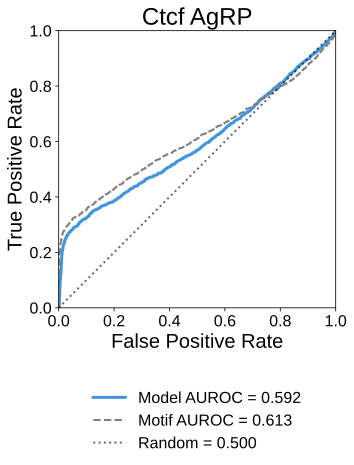

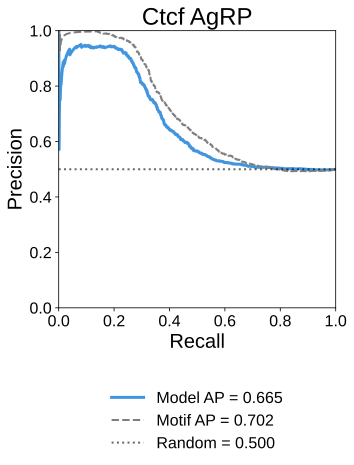

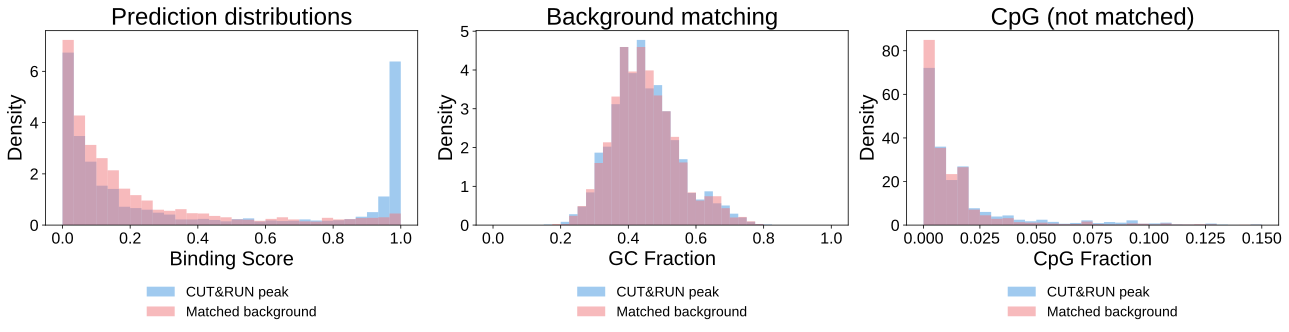

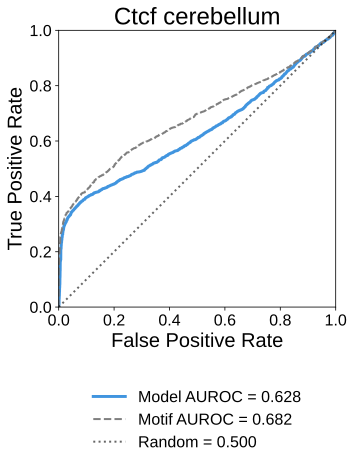

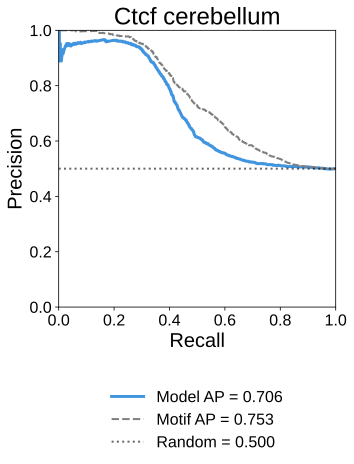

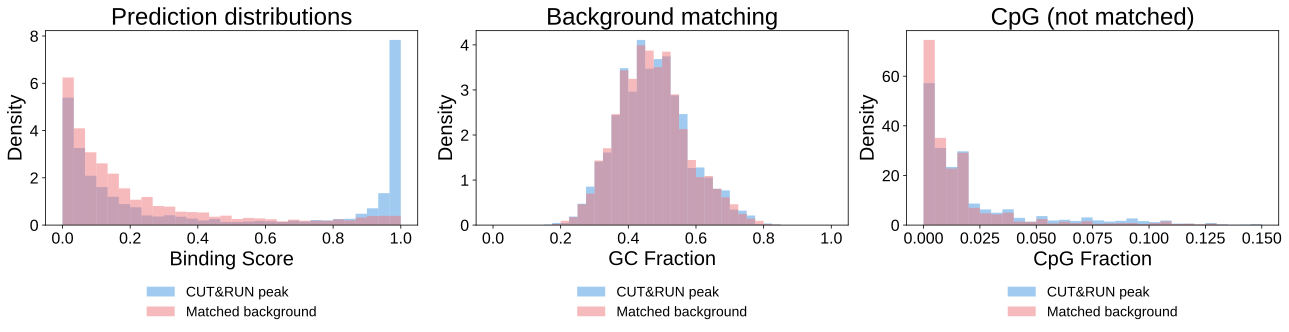

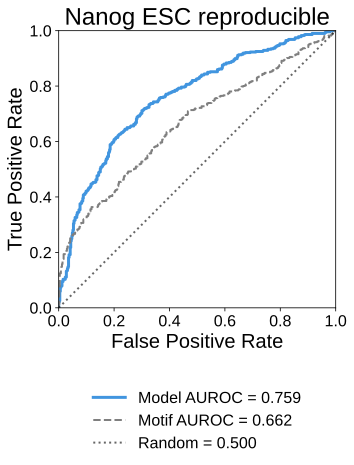

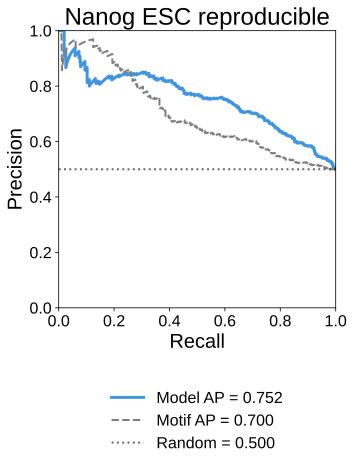

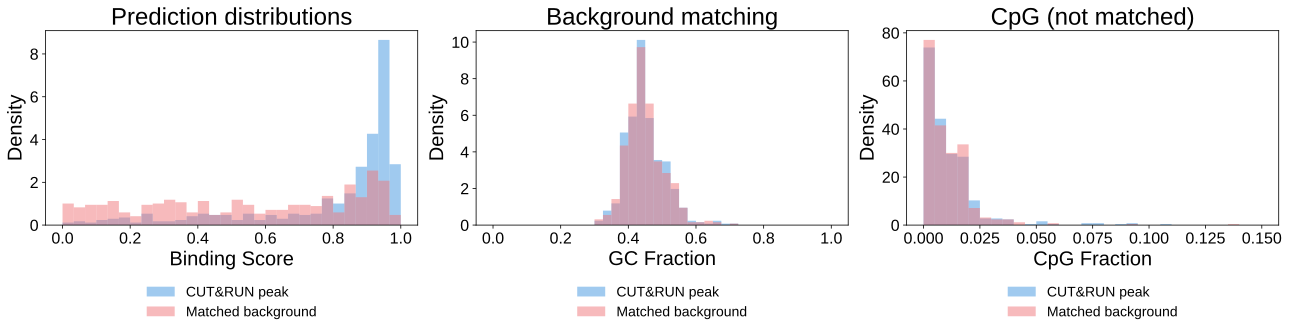

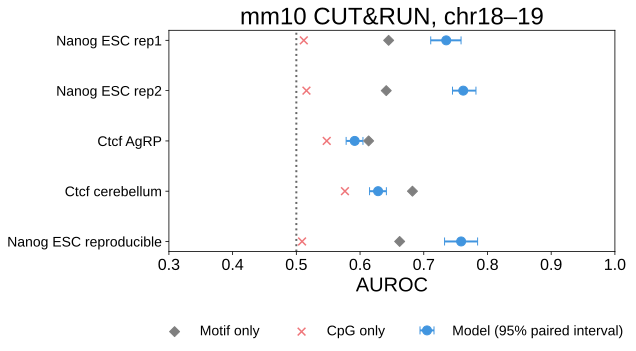

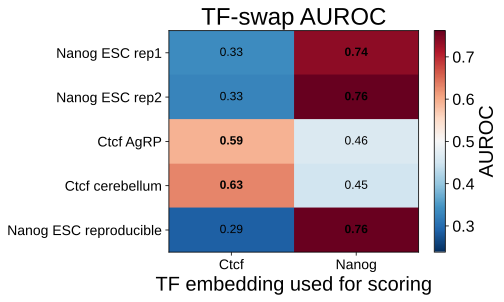

In [11]:
arial_font_path = TETHER_DIR / "fonts" / "Arial.ttf"
if arial_font_path.exists():
    font_manager.fontManager.addfont(str(arial_font_path))
    preferred_font = font_manager.FontProperties(fname=str(arial_font_path)).get_name()
else:
    preferred_font = "DejaVu Sans"
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [preferred_font, "DejaVu Sans"],
    "pdf.fonttype": 42, "svg.fonttype": "none",
    "axes.titlesize": 24, "axes.labelsize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16,
})
model_color = "#4195df"
motif_color = "#7f7f7f"
background_color = "#EF767A"

def save_evaluation_figure(figure, figure_stem):
    for extension in ("png", "pdf", "svg"):
        figure.savefig(evaluation_figure_dir / f"{figure_stem}.{extension}", dpi=300, bbox_inches="tight")

metrics_by_dataset = metric_summary_df.set_index("dataset")
for dataset_name, dataset_prediction_df in prediction_df.groupby("dataset", sort=False):
    dataset_metrics = metrics_by_dataset.loc[dataset_name]
    if dataset_metrics["role"] == "replicate":
        continue
    labels = dataset_prediction_df["label"].to_numpy()
    scores = dataset_prediction_df["binding_logit"].to_numpy()
    motif_scores = dataset_prediction_df["motif_score"].to_numpy()

    roc_figure, roc_axis = plt.subplots(figsize=(6, 5))
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, scores)
    roc_axis.plot(false_positive_rate, true_positive_rate, color=model_color, lw=3,
                  label=f"Model AUROC = {dataset_metrics['auroc']:.3f}")
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, motif_scores)
    roc_axis.plot(false_positive_rate, true_positive_rate, color=motif_color, lw=2, linestyle="--",
                  label=f"Motif AUROC = {dataset_metrics['motif_only_auroc']:.3f}")
    roc_axis.plot([0, 1], [0, 1], color="black", linestyle=":", lw=2, alpha=0.6, label="Random = 0.500")
    roc_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="False Positive Rate",
                 ylabel="True Positive Rate", title=dataset_name.replace("_", " "))
    roc_axis.set_aspect("equal")
    roc_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(roc_figure, f"{dataset_name}_roc")
    plt.show()
    plt.close(roc_figure)

    pr_figure, pr_axis = plt.subplots(figsize=(6, 5))
    precision, recall, _ = precision_recall_curve(labels, scores)
    pr_axis.plot(recall, precision, color=model_color, lw=3,
                 label=f"Model AP = {dataset_metrics['average_precision']:.3f}")
    precision, recall, _ = precision_recall_curve(labels, motif_scores)
    pr_axis.plot(recall, precision, color=motif_color, lw=2, linestyle="--",
                 label=f"Motif AP = {dataset_metrics['motif_only_average_precision']:.3f}")
    pr_axis.axhline(labels.mean(), color="black", linestyle=":", lw=2, alpha=0.6,
                    label=f"Random = {labels.mean():.3f}")
    pr_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
                title=dataset_name.replace("_", " "))
    pr_axis.set_aspect("equal")
    pr_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(pr_figure, f"{dataset_name}_precision_recall")
    plt.show()
    plt.close(pr_figure)

    diagnostic_figure, diagnostic_axes = plt.subplots(1, 3, figsize=(18, 5))
    for label, class_name, class_color in (
        (1, "CUT&RUN peak", model_color), (0, "Matched background", background_color),
    ):
        class_rows = dataset_prediction_df.loc[dataset_prediction_df["label"] == label]
        diagnostic_axes[0].hist(class_rows["binding_score"], bins=np.linspace(0, 1, 31),
                                density=True, alpha=0.5, color=class_color, label=class_name)
        diagnostic_axes[1].hist(class_rows["gc_fraction"], bins=np.linspace(0, 1, 41),
                                density=True, alpha=0.5, color=class_color, label=class_name)
        diagnostic_axes[2].hist(class_rows["cpg_fraction"], bins=np.linspace(0, 0.15, 31),
                                density=True, alpha=0.5, color=class_color, label=class_name)
    diagnostic_axes[0].set(xlabel="Binding Score", ylabel="Density", title="Prediction distributions")
    diagnostic_axes[1].set(xlabel="GC Fraction", ylabel="Density", title="Background matching")
    diagnostic_axes[2].set(xlabel="CpG Fraction", ylabel="Density", title="CpG (not matched)")
    for axis in diagnostic_axes:
        axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=14)
    diagnostic_figure.tight_layout()
    save_evaluation_figure(diagnostic_figure, f"{dataset_name}_diagnostics")
    plt.show()
    plt.close(diagnostic_figure)

# Summary: model AUROC with paired interval, and the single-feature baselines, for every dataset.
summary_order = metric_summary_df.iloc[::-1].reset_index(drop=True)
summary_figure, summary_axis = plt.subplots(figsize=(8, 0.5 * len(summary_order) + 1.5))
y_positions = np.arange(len(summary_order))
summary_axis.errorbar(
    summary_order["auroc"], y_positions,
    xerr=[summary_order["auroc"] - summary_order["auroc_ci_low"],
          summary_order["auroc_ci_high"] - summary_order["auroc"]],
    fmt="o", color=model_color, ms=9, lw=2, capsize=4, label="Model (95% paired interval)",
)
summary_axis.scatter(summary_order["motif_only_auroc"], y_positions, marker="D", s=50,
                     color=motif_color, label="Motif only", zorder=3)
summary_axis.scatter(summary_order["cpg_only_auroc"], y_positions, marker="x", s=60,
                     color=background_color, label="CpG only", zorder=3)
summary_axis.axvline(0.5, color="black", linestyle=":", lw=2, alpha=0.6)
summary_axis.set_yticks(y_positions, summary_order["dataset"].str.replace("_", " "), fontsize=14)
chromosome_label = f"{EVALUATION_CHROMOSOMES[0]}–{EVALUATION_CHROMOSOMES[-1].removeprefix('chr')}"
summary_axis.set(xlim=(0.3, 1.0), xlabel="AUROC", title=f"{GENOME} CUT&RUN, {chromosome_label}")
# Place the legend a fixed 0.85 inch below the axis so it clears the x label at any figure height.
axis_height_inches = summary_axis.get_position().height * summary_figure.get_figheight()
summary_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.85 / axis_height_inches),
                    frameon=False, fontsize=14, ncol=3)
save_evaluation_figure(summary_figure, "auroc_summary")
plt.show()
plt.close(summary_figure)

swap_values = tf_swap_matrix[EVALUATED_TFS]
swap_figure, swap_axis = plt.subplots(figsize=(1.3 * len(EVALUATED_TFS) + 3, 0.5 * len(swap_values) + 1.5))
# Diverging scale centered on random (0.5): values below 0.5 mean the embedding ranks peaks below background.
color_half_range = max(0.25, float((swap_values - 0.5).abs().max().max()))
image = swap_axis.imshow(swap_values.to_numpy(), cmap="RdBu_r", vmin=0.5 - color_half_range,
                         vmax=0.5 + color_half_range, aspect="auto")
for (row_index, column_index), value in np.ndenumerate(swap_values.to_numpy()):
    own_tf = metrics_by_dataset.loc[swap_values.index[row_index], "tf_name"]
    weight = "bold" if EVALUATED_TFS[column_index] == own_tf else "normal"
    swap_axis.text(column_index, row_index, f"{value:.2f}", ha="center", va="center", fontsize=12, fontweight=weight)
swap_axis.set_xticks(range(len(EVALUATED_TFS)), EVALUATED_TFS, fontsize=14)
swap_axis.set_yticks(range(len(swap_values)), swap_values.index.str.replace("_", " "), fontsize=14)
swap_axis.set(xlabel="TF embedding used for scoring", title="TF-swap AUROC")
swap_figure.colorbar(image, ax=swap_axis, label="AUROC")
save_evaluation_figure(swap_figure, "tf_swap_auroc")
plt.show()
plt.close(swap_figure)

## Reproducibility record and interpretation

The run records the checkpoint, input checksums, saved split audit, embedding check, motif choice, matching rules, package versions, compute host, and Slurm job. Prediction tables keep the exact evaluation row order and DNA sequences. Download commands are in `data/CUT&RUN_data/mm10/download_instructions.txt`.

Interpretation is limited to sequence discrimination for these TFs, assays, chromosomes, and backgrounds. The model receives no cell-state, accessibility, TF-expression, or cofactor measurements. A good result supports sequence-based enrichment at CUT&RUN peaks; it cannot establish cell-type-specific occupancy. The CTCF samples are author-filtered single libraries from neural tissue, and the NANOG replicates come from ES cells, so the two TFs differ in cell type and in replicate structure.

In [12]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

provenance_input_paths = [
    tf_dna_model_path, evaluation_windows_path,
    *sorted({cutrun_data_dir / filename for item in cutrun_dataset_definitions
             for filename in item["files"] if (cutrun_data_dir / filename).is_file()}),
    *[tf_dna_input_cache_dir / filename for filename in (
        "train_idx.pt", "val_idx.pt", "test_idx.pt", "edge_peak_idx.pt",
        "peak_id_to_idx.csv", "tf_name_to_idx.csv", "tf_masks.pt",
    )],
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz",
    cutrun_data_dir / f"{GENOME}.chrom.sizes",
    *[cutrun_data_dir / filename for filename in EXTRA_PROVENANCE_FILES],
    *[cutrun_data_dir / f"{series}_family.soft.gz" for series in geo_metadata_by_series],
    Path(str(genome_fasta_path) + ".fai"),
]
run_provenance = dict(
    completed_utc=datetime.now(timezone.utc).isoformat(),
    host=socket.gethostname(),
    slurm_job_id=os.environ.get("TF_DNA_CUTRUN_BATCH_JOB_ID", os.environ.get("SLURM_JOB_ID")),
    kernel_environment_slurm_job_id=os.environ.get("SLURM_JOB_ID"),
    genome=GENOME, checkpoint=str(tf_dna_model_path), tf_dna_cache=str(tf_dna_input_cache_dir), device=str(device),
    gpu=torch.cuda.get_device_name() if device.type == "cuda" else None,
    python=platform.python_version(), torch=torch.__version__,
    numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
    matplotlib=mpl.__version__, pysam=pysam.__version__,
    chromosomes=EVALUATION_CHROMOSOMES, random_seed=RANDOM_SEED,
    window_length=DNA_WINDOW_LENGTH, gc_tolerance=GC_MATCH_TOLERANCE,
    maximum_matching_attempts=MAXIMUM_MATCH_ATTEMPTS,
    inference_batch_size=INFERENCE_BATCH_SIZE, bootstrap_replicates=BOOTSTRAP_REPLICATES,
    score_orientation="forward genomic (primary); reverse complement reported",
    center="valid narrowPeak summit; midpoint for BED or invalid summit",
    tf_embedding_source="training cache tf_embeddings.pt with tf_masks.pt",
    embedding_check=embedding_check_df.to_dict(orient="records"),
    motifs=motif_records,
    datasets=[{key: value for key, value in item.items()} for item in cutrun_dataset_definitions],
    reference=dict(path=str(genome_fasta_path), size_bytes=genome_fasta_path.stat().st_size,
                   mtime_ns=genome_fasta_path.stat().st_mtime_ns,
                   validation=f"chromosome lengths match downloaded UCSC {GENOME} chromosome sizes"),
    file_sha256={str(path): sha256_file(path) for path in provenance_input_paths},
)
(evaluation_result_dir / "run_provenance.json").write_text(json.dumps(run_provenance, indent=2, default=str) + "\n")

chromosome_label = f"{EVALUATION_CHROMOSOMES[0]}–{EVALUATION_CHROMOSOMES[-1].removeprefix('chr')}"
interpretation_lines = [
    "### Observed results",
    "",
    f"All results compare {chromosome_label} CUT&RUN peaks with 1:1 chromosome- and GC-matched genomic background.",
    "",
    "| Dataset | Role | Positive windows | Model AUROC (95% paired interval) | Model AP | Motif-only AUROC | Model − motif (95% interval) | CpG-only AUROC |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for row in metric_summary_df.itertuples(index=False):
    interpretation_lines.append(
        f"| {row.dataset} | {row.role} | {row.positive_windows:,} | "
        f"{row.auroc:.3f} ({row.auroc_ci_low:.3f}–{row.auroc_ci_high:.3f}) | {row.average_precision:.3f} | "
        f"{row.motif_only_auroc:.3f} | {row.model_minus_motif_auroc:+.3f} "
        f"({row.model_minus_motif_auroc_ci_low:+.3f} to {row.model_minus_motif_auroc_ci_high:+.3f}) | "
        f"{row.cpg_only_auroc:.3f} |"
    )
interpretation_lines += [
    "",
    "Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. "
    "The intervals describe sampled loci and do not establish biological replicate uncertainty.",
    "",
    f"Predictions and methods records: {evaluation_result_dir}",
    f"Figures: {evaluation_figure_dir}",
]
interpretation_markdown = "\n".join(interpretation_lines)
(evaluation_result_dir / "results_summary.md").write_text(interpretation_markdown + "\n")
display(Markdown(interpretation_markdown))
genome_fasta.close()

### Observed results

All results compare chr18–19 CUT&RUN peaks with 1:1 chromosome- and GC-matched genomic background.

| Dataset | Role | Positive windows | Model AUROC (95% paired interval) | Model AP | Motif-only AUROC | Model − motif (95% interval) | CpG-only AUROC |
|---|---|---:|---:|---:|---:|---:|---:|
| Nanog_ESC_rep1 | replicate | 720 | 0.735 (0.711–0.759) | 0.738 | 0.645 | +0.090 (+0.058 to +0.122) | 0.512 |
| Nanog_ESC_rep2 | replicate | 1,042 | 0.762 (0.745–0.782) | 0.750 | 0.641 | +0.121 (+0.097 to +0.147) | 0.516 |
| Ctcf_AgRP | primary | 2,848 | 0.592 (0.578–0.605) | 0.665 | 0.613 | -0.022 (-0.035 to -0.008) | 0.548 |
| Ctcf_cerebellum | primary | 3,377 | 0.628 (0.615–0.641) | 0.706 | 0.682 | -0.054 (-0.066 to -0.043) | 0.576 |
| Nanog_ESC_reproducible | primary | 506 | 0.759 (0.733–0.785) | 0.752 | 0.662 | +0.096 (+0.058 to +0.131) | 0.509 |

Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. The intervals describe sampled loci and do not establish biological replicate uncertainty.

Predictions and methods records: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_testing_results/tf_dna_cutrun_mm10_mm10_3925194_epoch_21
Figures: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/tf_dna_cutrun_mm10_mm10_3925194_epoch_21

## Findings from the completed evaluation

All numbers are for chr18–19, which the saved-cache audit shows are absent from the training split (chr1–15) and the validation split (chr16–17). Each dataset is 1:1 positive/GC-matched background, so random AUROC and AP are 0.5. GC-only AUROC is 0.50–0.51 for every dataset, so the background matching worked. All five peak sets pass motif QC (PWM AUROC 0.61–0.68).

**NANOG (ES cells): the model ranks NANOG peaks above background and above a motif scan.** For the reproducible set, AUROC is **0.759** (506 pairs, 95% paired interval 0.733–0.785), the same as the earlier version of this notebook. Single replicates give 0.735 and 0.762, and chr18/chr19 give 0.747 and 0.773. The model is 0.096 above the CIS-BP PWM scan (interval +0.058 to +0.131). The strand-averaged score is higher than the forward-strand score (0.782 vs 0.759).

**TF identity matters strongly.** The Ctcf embedding ranks NANOG peaks *below* background (AUROC 0.29–0.33), and the Nanog embedding ranks CTCF peaks below background (0.45–0.46). Each TF's own embedding is clearly best on its own peaks.

**CTCF (AgRP neurons, cerebellum): weak, and below the motif scan.** AUROC is **0.592** (AgRP, 2,848 pairs, 0.578–0.605) and **0.628** (cerebellum, 3,377 pairs, 0.615–0.641). Both are *below* the PWM scan: −0.022 (−0.035 to −0.008) and −0.054 (−0.066 to −0.043). At threshold 0.5, sensitivity is 0.35–0.41 and specificity 0.87–0.88: the Ctcf embedding calls few windows bound.

**No-TF control: not available.** These GEO series deposit no IgG or untagged-antibody peaks, so the TF-independent part of the signal, measured with the anti-V5 control in hg38, cannot be measured in mm10. The TF-swap results above suggest it is smaller here.

**Comparison with hg38 (same analysis cells).** The lineage-restricted TFs score similarly (mm10 NANOG 0.759; hg38 EPAS1 0.775, HIF1A 0.751), and both beat or match their PWM scans. CTCF differs: mm10 3925194 is below the CTCF PWM, and hg38 3930720 is above it (0.684, +0.076). TF specificity also differs: out-of-family embeddings score 0.29–0.46 here but 0.52–0.56 on hg38 HIF peaks, and an hg38 no-TF control scores 0.65.